# Build a custom training table

Supply labels, row weights, and train, validation, and test assignments to Kumo Engine using a small synthetic retail graph.
Inspect the accepted rows, repair a missing split, fit a demonstration model, and score newly added customers.

Use a Linux CPU notebook prepared with the [Kumo Engine setup](https://docs.nvidia.com/sdgm/kumo-engine/get-started-with-kumo-engine/installation/linux-machine-deployment) and writable local scratch.
See [custom training tables](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/predictive-queries#use-supplied-training-rows) for the supplied-column contract.


## Install

Install Kumo Engine in this notebook kernel.

In [ ]:
%pip install -q kumo-engine

## Choose a workspace

The workspace defaults to `kumo_example_runs` under the current directory.
Set `KUMO_LOCAL_SSD` to use another writable local directory.
This cell creates a new directory on each run, with separate source, scratch, and output directories.
It does not replace existing data.
The final line prints the workspace and installed Kumo Engine version.

In [1]:
import importlib.metadata
import json
import os
from pathlib import Path
import tempfile

import pandas as pd
from IPython.display import display
import kumo.engine as kumo
from kumoapi.train import TrainingTableSpec
from kumoapi.typing import Stype
from kumo.engine.trainer.output_config import TrainingTableOutputConfig

LOCAL_SSD_ROOT = Path(os.environ.get("KUMO_LOCAL_SSD", str(Path.cwd() / "kumo_example_runs")))

LOCAL_SSD_ROOT.mkdir(parents=True, exist_ok=True)
if not LOCAL_SSD_ROOT.is_dir():
    raise FileNotFoundError(
        "Set KUMO_LOCAL_SSD or LOCAL_SSD_ROOT to a writable local directory."
    )
workspace = Path(tempfile.mkdtemp(prefix="kumo-custom-training-", dir=LOCAL_SSD_ROOT))
source_dir = workspace / "source"
output_dir = workspace / "outputs"
source_dir.mkdir()
output_dir.mkdir()
kumo.configure(scratch_dir=workspace / "scratch")
print("Kumo Engine:", importlib.metadata.version("kumo-engine"))
print("Workspace:", workspace)

/tmp/kumo-notebook-runtime/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Kumo Engine: 1.0.0.dev0+b840a3ed
Workspace: /tmp/kumo-notebook-runs/local_kumo_engine_custom_training_table/20261109T185541Z/kumo_example_runs/kumo-custom-training-dvskgpdr


## Generate synthetic example data

Run the next cell to create 50 customers and 150 transactions. `CUSTOMER_ID` links each transaction to `customers.ID`; customers 40–49 have no `CHURNED` label.
Reserve 10 more unlabeled customers and their 30 transactions in memory for batch inference. They stay out of the source files and training snapshot until **Batch predictions**.
You can skim the generation code; graph construction starts below.


In [2]:
customers_frame = pd.DataFrame({
    "ID": range(50),
    "CHURNED": pd.array(
        [bool(i % 2) for i in range(40)] + [None] * 10,
        dtype="boolean",
    ),
    "VISITS": [float(i % 7) for i in range(50)],
})
transactions_frame = pd.DataFrame({
    "TX_ID": range(150),
    "CUSTOMER_ID": [i % 50 for i in range(150)],
    "AMOUNT": [float(5 + (i * 7) % 40) for i in range(150)],
    "TIMESTAMP": pd.Timestamp("2025-01-01") + pd.to_timedelta(
        [i % 30 for i in range(150)], unit="D"
    ),
})
new_customers_frame = pd.DataFrame({
    "ID": range(50, 60),
    "CHURNED": pd.array([None] * 10, dtype="boolean"),
    "VISITS": [float(i % 7) for i in range(50, 60)],
})
new_transactions_frame = pd.DataFrame({
    "TX_ID": range(150, 180),
    "CUSTOMER_ID": [50 + (i - 150) % 10 for i in range(150, 180)],
    "AMOUNT": [float(5 + (i * 7) % 40) for i in range(150, 180)],
    "TIMESTAMP": pd.Timestamp("2025-01-01") + pd.to_timedelta(
        [i % 30 for i in range(150, 180)], unit="D",
    ),
})
customers_frame.to_parquet(source_dir / "customers.parquet", index=False)
transactions_frame.to_parquet(source_dir / "transactions.parquet", index=False)
print({"customers": len(customers_frame), "transactions": len(transactions_frame)})
print(customers_frame.head())
print("Reserved for inference:", len(new_customers_frame), "customers and",
      len(new_transactions_frame), "transactions")


{'customers': 50, 'transactions': 150}
   ID  CHURNED  VISITS
0   0    False     0.0
1   1     True     1.0
2   2    False     2.0
3   3     True     3.0
4   4    False     4.0
Reserved for inference: 10 customers and 30 transactions


## Build and explore the graph

Register the customer key, transaction key, transaction timestamp, and relationship.
The expected relationship runs from `transactions.CUSTOMER_ID` to `customers.ID`.
The custom training table in the next section will remain separate from these graph tables.

In [3]:
connector = kumo.FileConnector(root_dir=str(source_dir))
customers = kumo.Table.from_source_table(
    connector["customers.parquet"], primary_key="ID"
).infer_metadata()
transactions = kumo.Table.from_source_table(
    connector["transactions.parquet"], primary_key="TX_ID", time_column="TIMESTAMP"
).infer_metadata().with_column("CUSTOMER_ID", stype=Stype.ID)
graph = kumo.Graph(
    tables={"customers": customers, "transactions": transactions},
    edges=[kumo.Edge(src_table="transactions", fkey="CUSTOMER_ID", dst_table="customers")],
)
graph.validate()
print("Graph validation passed: two tables, one declared relationship.")

Graph validation passed: two tables, one declared relationship.


Inspect the graph's primary keys, transaction time, and foreign-key relationship before training.


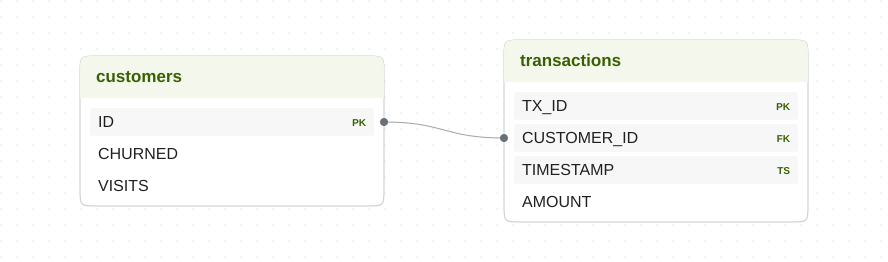

In [4]:
graph.visualize(show_cols=True)

Export the relationship diagram as SVG, then create the graph snapshot used for the supplied training rows and model fit.


In [5]:
_ = graph.visualize(output_dir / "retail-graph.svg", show_cols=True)
snapshot = graph.snapshot()
print("Snapshot:", snapshot.id)

/tmp/ipykernel_1346469/3493476439.py:2: UserWarning: The kumo.engine scratch directory /tmp/kumo-notebook-runs/local_kumo_engine_custom_training_table/20261109T185541Z/kumo_example_runs/kumo-custom-training-dvskgpdr/scratch is on Amazon EBS. Graph sampling and training-table generation read it randomly and run much slower there; local NVMe is recommended.
  snapshot = graph.snapshot()


ingest: table started phase="encode" table=customers


ingest: table producers complete phase="encode" table=customers rows=50 elapsed_ms=1


ingest: Ingestion stage progress phase=Encode table=customers shard=None progress_pct=100 current=1 total=1


ingest: table started phase="encode" table=transactions


ingest: table producers complete phase="encode" table=transactions rows=150 elapsed_ms=1


... (10 outputs left out)

ingest: finalize stage complete stage="finalize" elapsed_ms=0 elapsed=0ms


diskgraph ingest succeeded after 1 attempt(s) at 5 threads


diskgraph ingest completed: 2 node tables, 2 edge relations, 200 nodes, 300 edges


Snapshot: 4800345702bc9fd0fc72a3d70c0e95babf71e4c80665177fd481947598c2493a@d51d9e3e1a498c64


## Describe the prediction task

The task is to predict the customer's boolean `CHURNED` label.
This is a static query: each supplied training row contains the label for one customer, without a prediction timestamp.
The transaction timestamps are graph context and do not turn this task into a temporal query.
The task type should be `binary_classification`.

In [6]:
query = kumo.PredictiveQuery(
    graph, "PREDICT customers.CHURNED FOR EACH customers.ID"
)
print("Task type:", query.get_task_type())
print(query.validate())

Task type: binary_classification
ValidationResponse(warnings=[], errors=[], info_items=[])


## Supply labels, weights, and splits

Use `ENTITY1` for the customer's actual graph key and `TARGET1` for the supplied label.
The names are part of the custom-table contract, not the source graph's column names.
`WEIGHT` controls each row's contribution when weighted loss is selected.
`SPLIT` assigns `0` to training, `1` to validation, and `2` to test.

This static example uses different customers in each split: 20 training rows, 6 validation rows, and 4 test rows.
For a time-dependent problem, choose cutoffs that keep future information out of training rather than copying this split.

In [7]:
labeled_rows = pd.DataFrame({
    "ENTITY1": range(30),
    "TARGET1": [bool(i % 2) for i in range(30)],
    "WEIGHT": [1.0 + i % 3 for i in range(30)],
    "SPLIT": pd.array([0] * 20 + [1] * 6 + [2] * 4, dtype="Int64"),
})
labeled_rows.to_parquet(source_dir / "training.parquet", index=False)
print(labeled_rows.groupby("SPLIT").size().rename("rows"))
print(labeled_rows.head())

SPLIT
0    20
1     6
2     4
Name: rows, dtype: int64
   ENTITY1  TARGET1  WEIGHT  SPLIT
0        0    False     1.0      0
1        1     True     2.0      0
2        2    False     3.0      0
3        3     True     1.0      0
4        4    False     2.0      0


Materialize the supplied rows against the snapshot.
Pass the same `TrainingTableSpec` to model-plan suggestion later so it can account for the weight column.
The export in the next cell checks the accepted rows and all three split assignments.

In [8]:
spec = TrainingTableSpec(weight_col="WEIGHT", split_col="SPLIT")
training_table = kumo.TrainingTable.from_source_table(
    connector["training.parquet"], spec, pq=query, snapshot=snapshot
)
print("Required stages:", training_table.required_stages)

Required stages: ('train', 'val')


Check the rows Kumo actually accepted, rather than relying only on source counts.
Export the materialized table to a new output location and read its split assignments.
The output should still contain 30 rows with the `20 / 6 / 4` split shown above.

In [9]:
output_connector = kumo.FileConnector(root_dir=str(output_dir))
training_table.export(TrainingTableOutputConfig(
    connector=output_connector, table_name="accepted_training_rows"
))
accepted_rows = pd.read_parquet(output_dir / "accepted_training_rows")
print("Accepted rows:", len(accepted_rows))
print(accepted_rows.groupby("SPLIT").size().rename("rows"))

Accepted rows: 30
SPLIT
0    20
1     6
2     4
Name: rows, dtype: int64


## Recognize a skipped row

Append one extra synthetic row with no split assignment.
Kumo cannot place it into training, validation, or test, so this example should report one skipped row and keep the original 30 valid rows.
Read the reported reason before proceeding; a successful materialization does not mean every source row was accepted.

In [10]:
rows_with_missing_split = pd.concat([
    labeled_rows,
    pd.DataFrame({
        "ENTITY1": [30], "TARGET1": [False], "WEIGHT": [1.0],
        "SPLIT": pd.array([None], dtype="Int64"),
    }),
], ignore_index=True)
rows_with_missing_split.to_parquet(source_dir / "missing_split.parquet", index=False)
table_with_skipped_row = kumo.TrainingTable.from_source_table(
    connector["missing_split.parquet"], spec, pq=query, snapshot=snapshot
)
row_report = json.loads(table_with_skipped_row.manifest_path.read_text())["row_failures"]
print(json.dumps(row_report, indent=2))

custom-TT source: 1 of 31 rows were skipped; training on 30 rows. Reasons: split value is null[SPLIT]=1 on_error=skip_row_on_error


custom-TT source: 1 of 31 rows were skipped; training on 30 rows. Reasons: null split[SPLIT]=1


{
  "on_error": "skip_row_on_error",
  "rows_read": 31,
  "skipped_rows": 1,
  "by_condition": [
    {
      "condition": "null_split",
      "column": "SPLIT",
      "count": 1,
      "samples": [
        "part-00000.parquet row group 0 row 30"
      ]
    }
  ]
}


Correct the missing split before using that row.
Here the extra customer belongs to the training group by design, so assign `0` and materialize a new file.
The corrected export should contain 31 rows: 21 train, 6 validation, and 4 test.
Do not assign a split automatically for real data until you have decided which population or time boundary it belongs to.

In [11]:
repaired_rows = rows_with_missing_split.copy()
repaired_rows.loc[repaired_rows["ENTITY1"] == 30, "SPLIT"] = 0
repaired_rows.to_parquet(source_dir / "repaired_training.parquet", index=False)
repaired_training_table = kumo.TrainingTable.from_source_table(
    connector["repaired_training.parquet"], spec, pq=query, snapshot=snapshot
)
repaired_training_table.export(TrainingTableOutputConfig(
    connector=output_connector, table_name="repaired_training_rows"
))
repaired_accepted_rows = pd.read_parquet(output_dir / "repaired_training_rows")
print("Accepted rows after repair:", len(repaired_accepted_rows))
print(repaired_accepted_rows.groupby("SPLIT").size().rename("rows"))

Accepted rows after repair: 31
SPLIT
0    21
1     6
2     4
Name: rows, dtype: int64


## Fit a small model

Fit the original, fully specified 30-row table with its explicit snapshot.
The FAST model plan enables weighted loss and uses one experiment without refitting.
Refits and explanations are disabled to keep this module focused on supplied training rows.
These settings demonstrate that the table reaches training; use a proper training and evaluation budget for your own problem.

In [12]:
from kumoapi.model_plan import RunMode

model_plan = query.suggest_model_plan(snapshot, train_table_spec=spec, run_mode=RunMode.FAST)
model_plan.optimization.weight_mode = ["weighted_loss"]
model_plan.training_job.num_experiments = 1
model_plan.training_job.refit_trainval = False
model_plan.training_job.refit_full = False
model_plan.training_job.disable_explain = True
trainer = kumo.Trainer(model_plan=model_plan, accelerator="cpu")
fit_result = trainer.fit(training_table, snapshot=snapshot)
print("Synthetic-data metrics — demonstration only")
print(pd.Series(fit_result.metrics, name="demonstration_metric"))


[I 2026-11-09 18:55:52,058] A new study created in memory with name: no-name-041e7aec-24c0-4114-b8ed-965cea1c18f7


GPU available: False, used: False


TPU available: False, using: 0 TPU cores



  | Name           | Type                     | Params | Mode  | FLOPs
----------------------------------------------------------------------------
0 | target_encoder | CategoricalTargetEncoder | 0      | train | 0    
1 | metric_store   | MetricStore              | 0      | train | 0    
2 | loss           | BinaryCrossEntropyLoss   | 0      | train | 0    
3 | calibrator     | PlatScaling              | 2      | train | 0    
4 | encoder        | HeteroTensorFrameEncoder | 5.5 K  | train | 0    
5 | model          | HeteroGNN                | 50.2 K | train | 0    
6 | head           | NodePredHead             | 65     | train | 0    
----------------------------------------------------------------------------
55.7 K    Trainable params
0         Non-trainable params
55.7 K    Total params
0.223     Total estimated model params size (MB)
101       Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

... (59 outputs left out)

Testing DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 114.56it/s]

Testing DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 15.35it/s] 


────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
         test_ap                   0.75
       test_auprc           0.7083333730697632
       test_auroc                   0.5
        test_loss           0.7736071944236755
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


Synthetic-data metrics — demonstration only
val_loss       2.425004
val_ap         0.383333
val_auprc      0.300000
val_auroc      0.000000
test_loss      0.773607
test_ap        0.750000
test_auprc     0.708333
test_auroc     0.500000
train_loss     0.107149
train_ap       1.000000
train_auprc    1.000000
train_auroc    1.000000
Name: demonstration_metric, dtype: float64


## Batch predictions

Add the reserved customers and their transaction history to the graph, then reuse the fitted model on a new snapshot. These customers were absent from the original graph and all training, validation, and test rows; their `CHURNED` values remain unknown. No further training is needed.


In [13]:
assert set(new_customers_frame.ID).isdisjoint(customers_frame.ID)
assert set(new_customers_frame.ID).isdisjoint(labeled_rows.ENTITY1)
assert set(new_transactions_frame.TX_ID).isdisjoint(transactions_frame.TX_ID)
assert new_customers_frame.CHURNED.isna().all()
assert new_transactions_frame.CUSTOMER_ID.isin(new_customers_frame.ID).all()

updated_customers = pd.concat([customers_frame, new_customers_frame], ignore_index=True)
updated_transactions = pd.concat([transactions_frame, new_transactions_frame], ignore_index=True)
updated_customers.to_parquet(source_dir / "customers.parquet", index=False)
updated_transactions.to_parquet(source_dir / "transactions.parquet", index=False)
scoring_snapshot = graph.snapshot()
assert scoring_snapshot.id != snapshot.id

display(pd.DataFrame({
    "original_rows": [len(customers_frame), len(transactions_frame)],
    "new_rows": [len(new_customers_frame), len(new_transactions_frame)],
    "scoring_graph_rows": [len(updated_customers), len(updated_transactions)],
}, index=["customers", "transactions"]))


ingest: table started phase="encode" table=customers


ingest: table producers complete phase="encode" table=customers rows=60 elapsed_ms=1


ingest: Ingestion stage progress phase=Encode table=customers shard=None progress_pct=100 current=1 total=1


ingest: table started phase="encode" table=transactions


ingest: table producers complete phase="encode" table=transactions rows=180 elapsed_ms=1


ingest: Ingestion stage progress phase=Encode table=transactions shard=None progress_pct=100 current=1 total=1


... (9 outputs left out)

ingest: finalize stage complete stage="finalize" elapsed_ms=0 elapsed=0ms


diskgraph ingest succeeded after 1 attempt(s) at 5 threads


diskgraph ingest completed: 2 node tables, 2 edge relations, 240 nodes, 360 edges


,original_rows,new_rows,scoring_graph_rows
customers,50,10,60
transactions,150,30,180


### Prepare the scoring population

A [custom prediction table](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/making-predictions) supplies only the 10 new customer IDs, with no labels, weights, or split assignments. Selecting IDs explicitly keeps the original unlabeled customers 40–49 out of this batch.


In [14]:
scoring_rows = new_customers_frame[["ID"]].rename(columns={"ID": "ENTITY1"})
scoring_rows.to_parquet(source_dir / "scoring_population.parquet", index=False)
prediction_table = kumo.PredictionTable.from_source_table(
    connector["scoring_population.parquet"],
    pq=query,
    snapshot=scoring_snapshot,
    plan=trainer.training_table_generation_plan,
)
accepted_scoring_rows = pd.read_parquet(prediction_table.table_path)
assert accepted_scoring_rows.ENTITY1.is_unique
assert set(accepted_scoring_rows.ENTITY1) == set(new_customers_frame.ID)
assert not any(column.startswith("TARGET") for column in accepted_scoring_rows)
display(accepted_scoring_rows[["ENTITY1"]])


,ENTITY1
0,50
1,51
2,52
3,53
4,54
5,55
6,56
7,57
8,58
9,59


### Score the new records

Pass the materialized prediction table and refreshed snapshot to the same trainer used above. One call scores the whole batch with the existing model weights.


In [15]:
prediction_result = trainer.predict(
    prediction_table,
    snapshot=scoring_snapshot,
    binary_classification_threshold=0.5,
)
batch_scores = prediction_result.frame


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


Restoring states from the checkpoint path at file:///tmp/kumo-notebook-runs/local_kumo_engine_custom_training_table/20261109T185541Z/kumo_example_runs/kumo-custom-training-dvskgpdr/scratch/trainers/fb9cea59c730453db14ce4c4a38fde83/runs/fb9cea59c730453db14ce4c4a38fde83-predict-0878d71d4bcc4e178bac732cc76620a8/model_bundle/model/checkpoint/step=0.ckpt


Loaded model weights from the checkpoint at file:///tmp/kumo-notebook-runs/local_kumo_engine_custom_training_table/20261109T185541Z/kumo_example_runs/kumo-custom-training-dvskgpdr/scratch/trainers/fb9cea59c730453db14ce4c4a38fde83/runs/fb9cea59c730453db14ce4c4a38fde83-predict-0878d71d4bcc4e178bac732cc76620a8/model_bundle/model/checkpoint/step=0.ckpt


Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 72.84it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 56.50it/s]

### Inspect and save the predictions

Expect one row per new customer. `ENTITY` is the customer ID, `True_PROB` is the probability of `CHURNED=True`, and `TARGET_PRED` applies the 0.5 threshold. Match results by ID, verify probability ranges, and save the full batch as Parquet. These synthetic scores illustrate inference, not model quality.


In [16]:
expected = scoring_rows.rename(columns={"ENTITY1": "ENTITY"})
aligned = expected.merge(batch_scores, on="ENTITY", how="outer", validate="one_to_one", indicator=True)
assert aligned._merge.eq("both").all()
assert batch_scores.True_PROB.between(0, 1).all()
assert batch_scores.False_PROB.between(0, 1).all()
assert (batch_scores.True_PROB + batch_scores.False_PROB - 1).abs().le(1e-6).all()
assert batch_scores.TARGET_PRED.eq(batch_scores.True_PROB.gt(0.5)).all()

prediction_path = output_dir / "new_customer_predictions.parquet"
batch_scores.to_parquet(prediction_path, index=False)
pd.testing.assert_frame_equal(batch_scores, pd.read_parquet(prediction_path))
display(batch_scores[["ENTITY", "True_PROB", "TARGET_PRED"]].sort_values("ENTITY"))
print("Scored newly added customers:", len(batch_scores))
print("Saved predictions:", prediction_path)


,ENTITY,True_PROB,TARGET_PRED
0,50,0.495686,False
5,51,0.495846,False
1,52,0.495849,False
6,53,0.496079,False
2,54,0.496287,False
7,55,0.496198,False
3,56,0.495682,False
8,57,0.495851,False
4,58,0.495755,False
9,59,0.496035,False


Scored newly added customers: 10
Saved predictions: /tmp/kumo-notebook-runs/local_kumo_engine_custom_training_table/20261109T185541Z/kumo_example_runs/kumo-custom-training-dvskgpdr/outputs/new_customer_predictions.parquet


## Apply the workflow to your data

Use explicit training splits for evaluation, then select a separate population when new records arrive. Refresh the graph snapshot before scoring those records with the fitted model.

For an end-to-end example, see [transaction screening and batch predictions](../../fsi/notebooks/local_kumo_engine_synthetic_transaction_screening.ipynb#Batch-predictions).
For query design, see [static versus temporal queries](local_kumo_engine_static_and_temporal_queries.ipynb).
Keep the printed workspace to inspect the exported tables, predictions, and graph; its scratch files are local to this machine and are not a durable model backup.
